# Краткий обзор основных библиотек:

NumPy:
- Базовая библиотека для научных вычислений в Python.  
- Предоставляет многомерный массив ndarray, векторизованные операции, линалг, генераторы случайных чисел.  

Pandas:
- Высокоуровневая библиотека для работы с табличными данными (DataFrame, Series).  
- Удобная загрузка/сохранение данных, фильтрация, группировка, агрегация, работа с временными рядами.  

Scikit‑learn:
- Набор алгоритмов машинного обучения (классификация, регрессия, кластеризация, понижение размерности и т. д.).  
- Единый API: .fit(), .transform(), .fit_predict(), интеграция с пайплайнами.  

umap-learn (UMAP):
- Алгоритм понижения размерности и manifold‑обучения (Uniform Manifold Approximation and Projection).  
- Хорошо подходит для визуализации высокоразмерных данных и как этап препроцессинга перед кластеризацией.  


In [67]:
# %pip install numpy pandas scikit-learn matplotlib seaborn ipywidgets
# %pip install umap-learn

In [1]:
# ===== Импорт библиотек =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# датасет о градации телефонов по ценовому диапазону в зависимости от их характеристик
MOBILE_PRICE_DATASET = "price_mobile_phones.csv"

In [3]:
# df_source = pd.read_csv(MOBILE_PRICE_DATASET)
df = pd.read_csv(MOBILE_PRICE_DATASET)

In [4]:
# ===== Первичный анализ структуры данных =====
print("Первые 5 строк:")
print(df.head())  # быстрое представление структуры табличных данных.

print("\nИнформация о DataFrame:")
print(df.info())  # типы столбцов, количество непустых значений.

print("\nОписательная статистика по числовым признакам:")
print(df.describe())  # среднее, стандартное отклонение, квартили и т. д.

print("\nРаспределение классов:")
print(df["price_range"].value_counts())  # баланс классов для задачи классификации.


Первые 5 строк:
   battery_power  blue  clock_speed  dual_sim  fc  four_g  int_memory  m_dep  \
0            842     0          2.2         0   1       0           7    0.6   
1           1021     1          0.5         1   0       1          53    0.7   
2            563     1          0.5         1   2       1          41    0.9   
3            615     1          2.5         0   0       0          10    0.8   
4           1821     1          1.2         0  13       1          44    0.6   

   mobile_wt  n_cores  ...  px_height  px_width   ram  sc_h  sc_w  talk_time  \
0        188        2  ...         20       756  2549     9     7         19   
1        136        3  ...        905      1988  2631    17     3          7   
2        145        5  ...       1263      1716  2603    11     2          9   
3        131        6  ...       1216      1786  2769    16     8         11   
4        141        2  ...       1208      1212  1411     8     2         15   

   three_g  touch_scre

Описание признаков: <p>
battery_power - емкость аккумулятора <p>
blue          - наличие bluetooth <p>
clock_speed   - быстрота выполнения команд микропроцессором <p>
dual_sim      - возможность установления двух сим карт <p>
fc            - фронтальная камера в мп <p>
four_g        - наличие 4G <p>
int_memory    - объем встроенной памяти <p>
m_dep         - толщина телефона <p>
mobile_wt     - масса телефона <p>
n_cores       - количество ядер процессора <p>
pc            - основная камера в мп <p>
px_height     - высота разрешения в пикселях <p>
px_width      - ширина разрешения в пикселях <p>
ram           - объем ОЗУ <p>
sc_h          - высота экрана <p>
sc_w          - ширина экрана <p>
talk_time     - самый длительный срок службы одного заряда аккумулятора <p>
three_g       - наличие 3G <p>
touch_screen  - наличие сенсорного экрана <p>
wifi          - возможность подключаться к Wi-Fi <p>
<p>
-----------------------------------------------------------------------
<p>
price_range   - ценовая категория (это целевая переменная со значением 0 (низкая стоимость), 1 (средняя стоимость), 2 (высокая стоимость) и 3 (очень высокая стоимость))

In [5]:
# ===== Простые визуализации =====
sns.set(style="whitegrid")

In [6]:
# были отобраны 2 класса: 0 (низкая стоимость), 3 (очень высокая стоимость) для более наглядной визуализации
df = df[(df['price_range'] == 0) | (df['price_range'] == 3)]

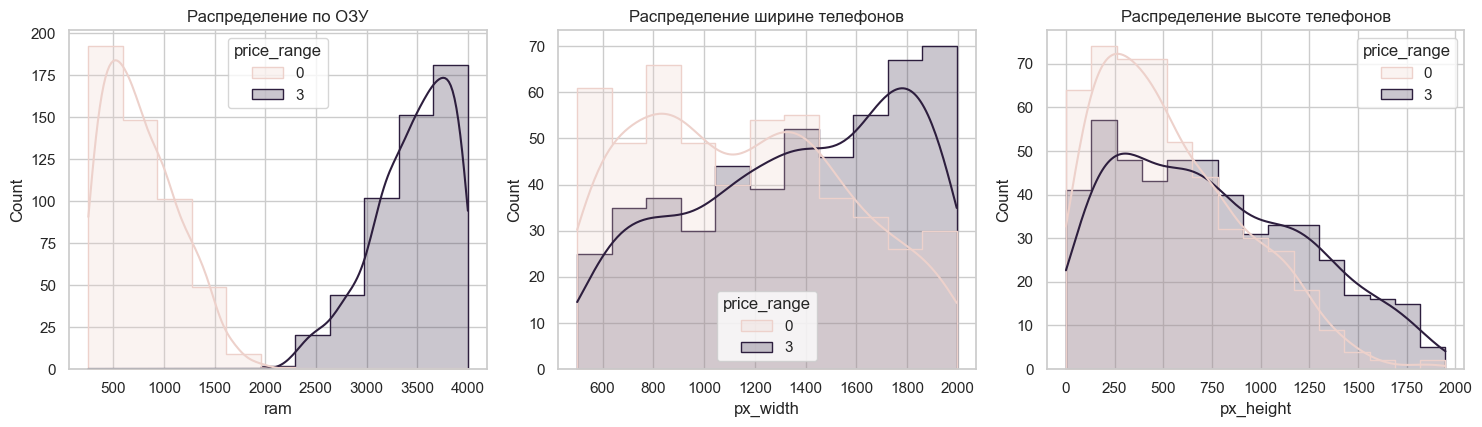

In [8]:
# Диаграммы распределения ОЗУ, ширины телефонов (по пикселям), высоты телефонов (по пикселям) по ценовым категориям

plt.figure(figsize=(15, 8))
plt.subplot(2, 3, 1)
sns.histplot(
    data=df,
    x="ram",
    hue="price_range",
    kde=True, # вкл. функция плотности распределения
    element="step"
)
plt.title("Распределение по ОЗУ")

plt.subplot(2, 3, 2)
sns.histplot(
    data=df,
    x="px_width",
    hue="price_range",
    kde=True, # вкл. функция плотности распределения
    element="step"
)
plt.title("Распределение ширине телефонов")

plt.subplot(2, 3, 3)
sns.histplot(
    data=df,
    x="px_height",
    hue="price_range",
    kde=True, # вкл. функция плотности распределения
    element="step"
)
plt.title("Распределение высоте телефонов")


plt.tight_layout()
plt.show()

In [9]:
df.columns.tolist()

['battery_power',
 'blue',
 'clock_speed',
 'dual_sim',
 'fc',
 'four_g',
 'int_memory',
 'm_dep',
 'mobile_wt',
 'n_cores',
 'pc',
 'px_height',
 'px_width',
 'ram',
 'sc_h',
 'sc_w',
 'talk_time',
 'three_g',
 'touch_screen',
 'wifi',
 'price_range']

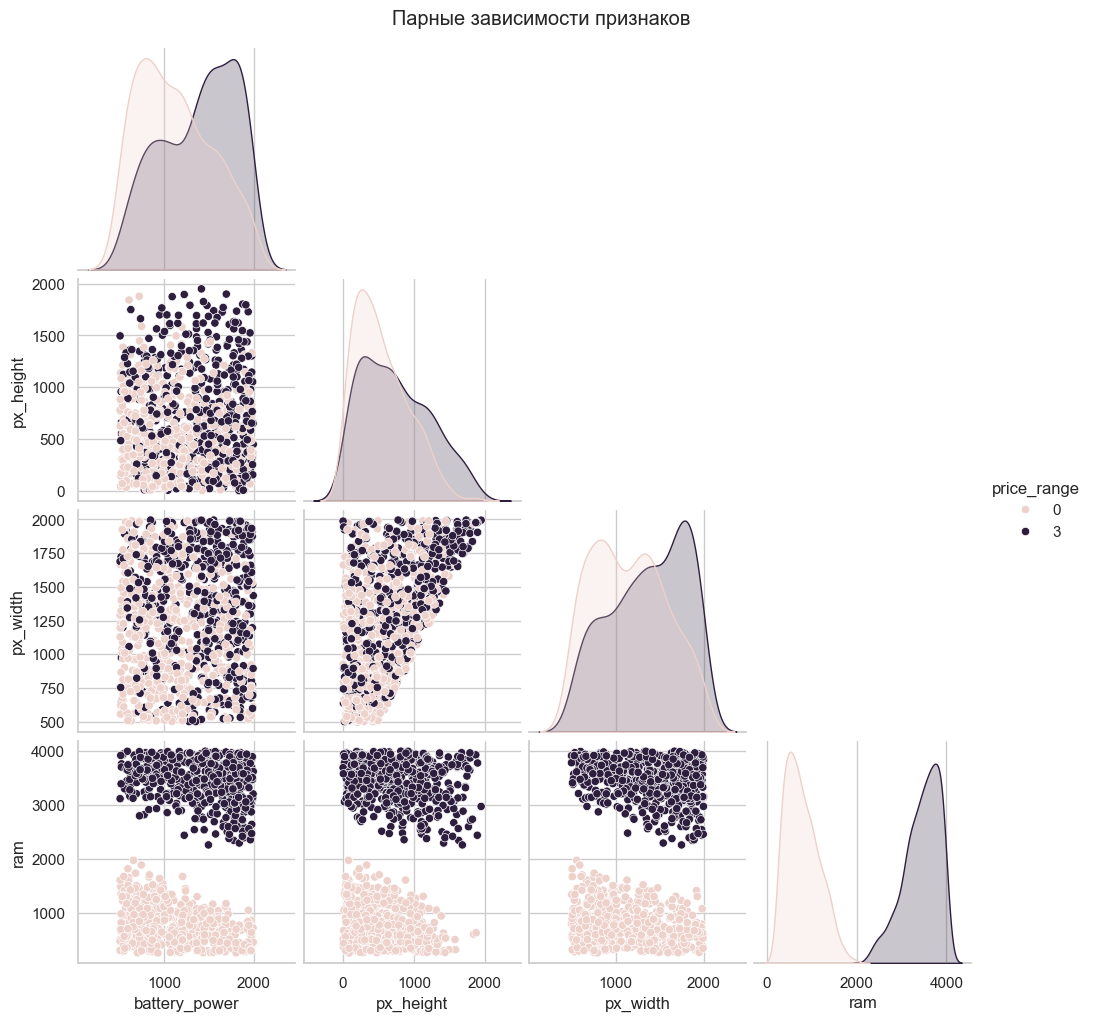

In [10]:
# Парные диаграммы признаков
sns.pairplot(
    df,
    vars=['battery_power', 'px_height', 'px_width', 'ram'],
    hue="price_range",
    corner=True
)
plt.suptitle("Парные зависимости признаков", y=1.02)
plt.show()

In [11]:
try:
    import umap  # pip install umap-learn
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False

C:\Users\Seva\AppData\Roaming\Python\Python312\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\Seva\AppData\Local\Temp\ipykernel_9052\3145806729.py:30: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Seva\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


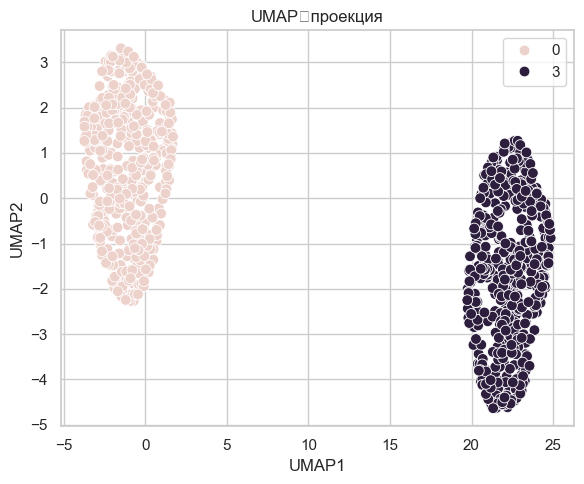

In [ ]:
# ===== UMAP с оптимизированными параметрами для разделения по статусу =====

if HAS_UMAP:
    reducer = umap.UMAP(
        n_neighbors=20,
        min_dist=0.3, # плотность расположения точек
        n_components=2,
        random_state=42)

    feature_cols = [col for col in df.columns if col != 'price_range']
    embedding = reducer.fit_transform(df[feature_cols].values)

    umap_df = pd.DataFrame(
        embedding,
        columns=["UMAP1", "UMAP2"]
    )
    umap_df["price_range"] = df["price_range"].values

    plt.figure(figsize=(6, 5))
    sns.scatterplot(
        data=umap_df,
        x="UMAP1",
        y="UMAP2",
        hue="price_range",
        s=60
    )
    plt.title("UMAP‑проекция")
    plt.legend()
    plt.tight_layout()
    plt.show()

Для UMAP обычно сначала масштабируют признаки, например с помощью StandardScaler из scikit‑learn, а затем уже подают их в UMAP.​

Простой пример со StandardScaler

In [13]:
from sklearn.preprocessing import StandardScaler

X = df[feature_cols].values       # признаки
y = df["price_range"].values     # классы (0, 3).

# 2. Стандартизация признаков: (x - mean) / std.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # возвращает numpy-массив того же размера.

In [14]:
# 3. UMAP на стандартизованных данных
umap_model = umap.UMAP(
    n_neighbors=20,
    min_dist=0.1,
    n_components=2,
    random_state=42
)  # базовые параметры UMAP.

X_umap = umap_model.fit_transform(X_scaled)  # понижение размерности до 2D.

C:\Users\Seva\AppData\Roaming\Python\Python312\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


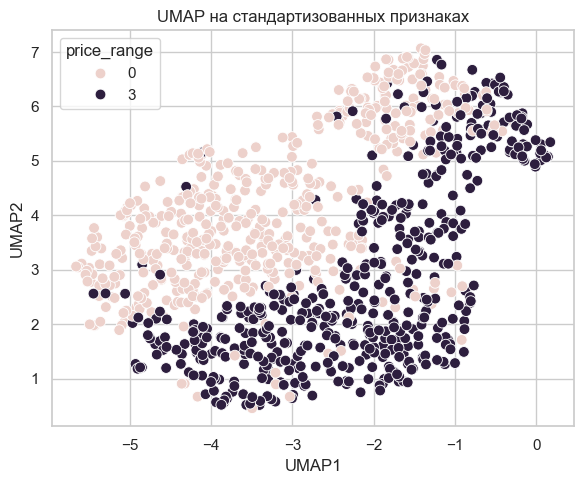

In [15]:
# 4. Визуализация результата
umap_df = pd.DataFrame(
    X_umap,
    columns=["UMAP1", "UMAP2"]
)
umap_df["price_range"] = y

plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="price_range",
    s=60
)
plt.title("UMAP на стандартизованных признаках")
plt.tight_layout()
plt.show()

* Стандартизатор обучается только на матрице признаков X и сохраняет среднее и стандартное отклонение для каждого признака.
​

* В UMAP подаётся уже X_scaled, а не исходные значения, что делает метрику расстояния более корректной, когда признаки в разных шкалах.


UMAP умеет работать напрямую с разрежёнными матрицами, а стандартизировать их нужно аккуратно, чтобы не разрушить разрежённость.


UMAP принимает sparse‑матрицы (CSR/CSC) и не требует предварительного перевода их в неразреженные матрицы.
​

При стандартизации разреженных данных нельзя вычитать среднее, иначе нули превращаются в ненули и матрица перестаёт быть разрежённой.
​

Для таких случаев в StandardScaler устанавливают with_mean=False, чтобы делить только на стандартное отклонение.


In [16]:
from scipy.sparse import csr_matrix, random

# Создание разреженной матрицы с заданным размером и заполнением
n_rows = 1000  # количество строк (образцов)
n_cols = 5000  # количество столбцов (признаков)
density = 0.01  # плотность (процент ненулевых элементов)

# Способ 1: Создание случайной разреженной матрицы
X_sparse = random(n_rows, n_cols, density=density, format='csr')

print(f"Разреженная матрица {n_rows}x{n_cols}")
print(f"Плотность: {density*100:.1f}%")
print(f"Количество ненулевых элементов: {X_sparse.nnz}")
print(f"Тип матрицы: {type(X_sparse)}")

Разреженная матрица 1000x5000
Плотность: 1.0%
Количество ненулевых элементов: 50000
Тип матрицы: <class 'scipy.sparse._csr.csr_matrix'>


In [17]:
 # 1. Стандартизация разрежённых данных
scaler = StandardScaler(
    with_mean=False,   # важно: не вычитать среднее для sparse.
    with_std=True
)
X_scaled = scaler.fit_transform(X_sparse)  # остаётся sparse‑матрицей.

# 2. UMAP на стандартизованных sparse‑данных
umap_model = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="cosine",   # популярная метрика для текстовых/разрежённых данных.
    #random_state=42
    n_jobs=-1
)
X_embedded = umap_model.fit_transform(X_scaled)  # получается плотный массив (n_samples, 2).


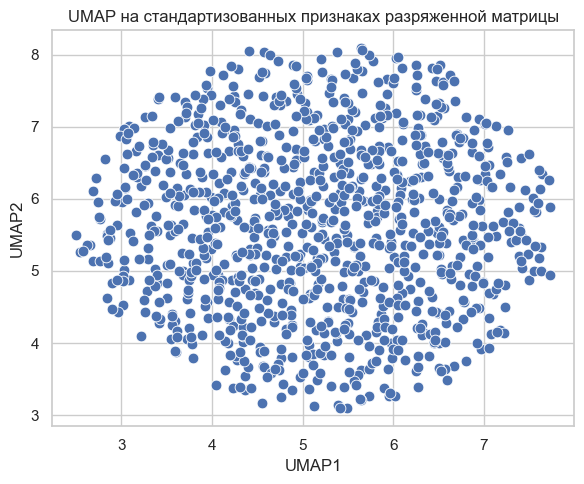

In [18]:
# 4. Визуализация результата
umap_df = pd.DataFrame(
    X_embedded,
    columns=["UMAP1", "UMAP2"]
)

plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    #hue="target_name",
    s=60
)
plt.title("UMAP на стандартизованных признаках разряженной матрицы")
plt.tight_layout()
plt.show()

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib import colors
import seaborn as sns
from sklearn.datasets import make_classification, make_blobs, make_moons
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import MDS, Isomap, SpectralEmbedding, LocallyLinearEmbedding, TSNE
from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.cluster import KMeans, DBSCAN
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots


import warnings
warnings.filterwarnings('ignore')


try:
    import umap  # pip install umap-learn
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False

In [20]:
# Настройки отображения
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['figure.dpi'] = 100

In [22]:
from multidim_visualization import HighDimVisualizer

In [23]:
feature_cols

['battery_power',
 'blue',
 'clock_speed',
 'dual_sim',
 'fc',
 'four_g',
 'int_memory',
 'm_dep',
 'mobile_wt',
 'n_cores',
 'pc',
 'px_height',
 'px_width',
 'ram',
 'sc_h',
 'sc_w',
 'talk_time',
 'three_g',
 'touch_screen',
 'wifi']

Выберите тип данных для визуализации:
1. Синтетические классификационные данные
2. Комплексные данные (кластеры + полумесяцы)
3. Данные о телефонах

Информация о данных:
  Размер: (1000, 20)
  Количество классов: 2
  Количество признаков: 20
  Минимум: 0.000, Максимум: 3998.000
  Среднее: 274.532, Стандартное отклонение: 672.458
ПОЛНАЯ ВИЗУАЛИЗАЦИЯ МНОГОМЕРНЫХ ДАННЫХ

1. Парные диаграммы рассеяния (PairPlot)


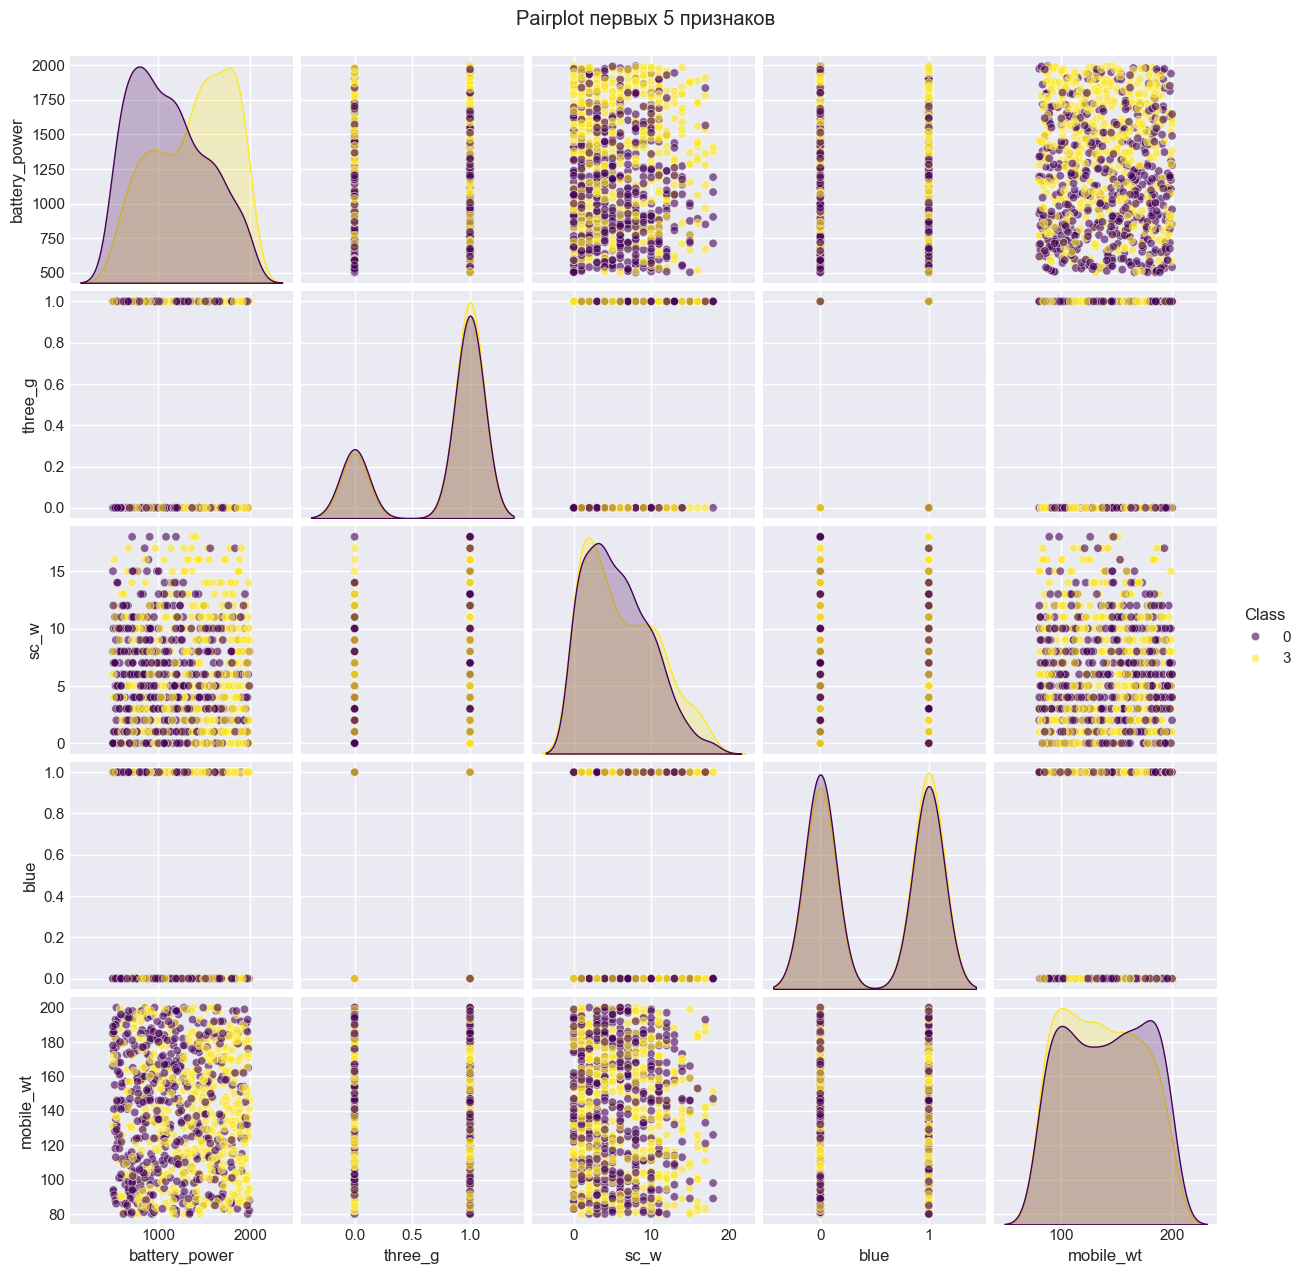


2. Тепловая карта корреляций


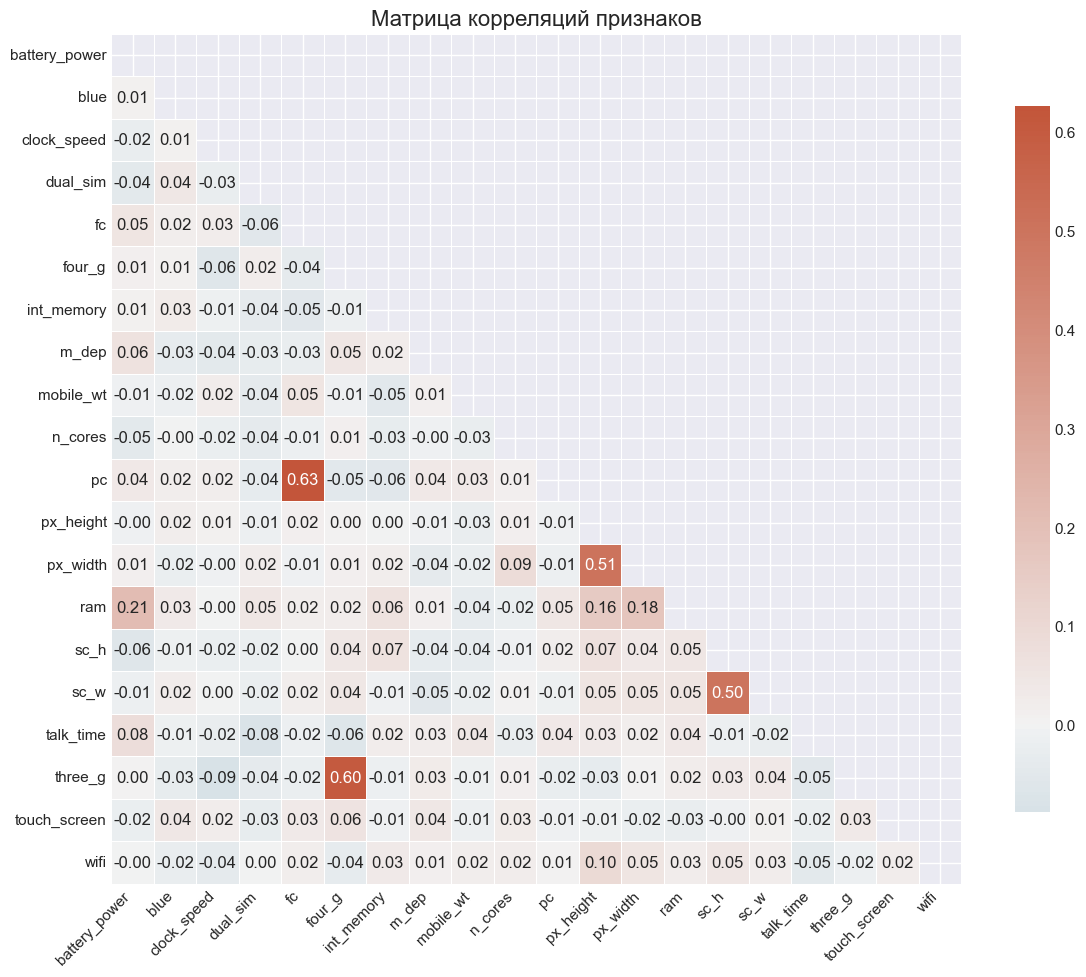


3. Визуализация PCA (2D и 3D)
Объясненная дисперсия: [0.77840476 0.11184974 0.07110329]
Суммарная объясненная дисперсия: 0.961


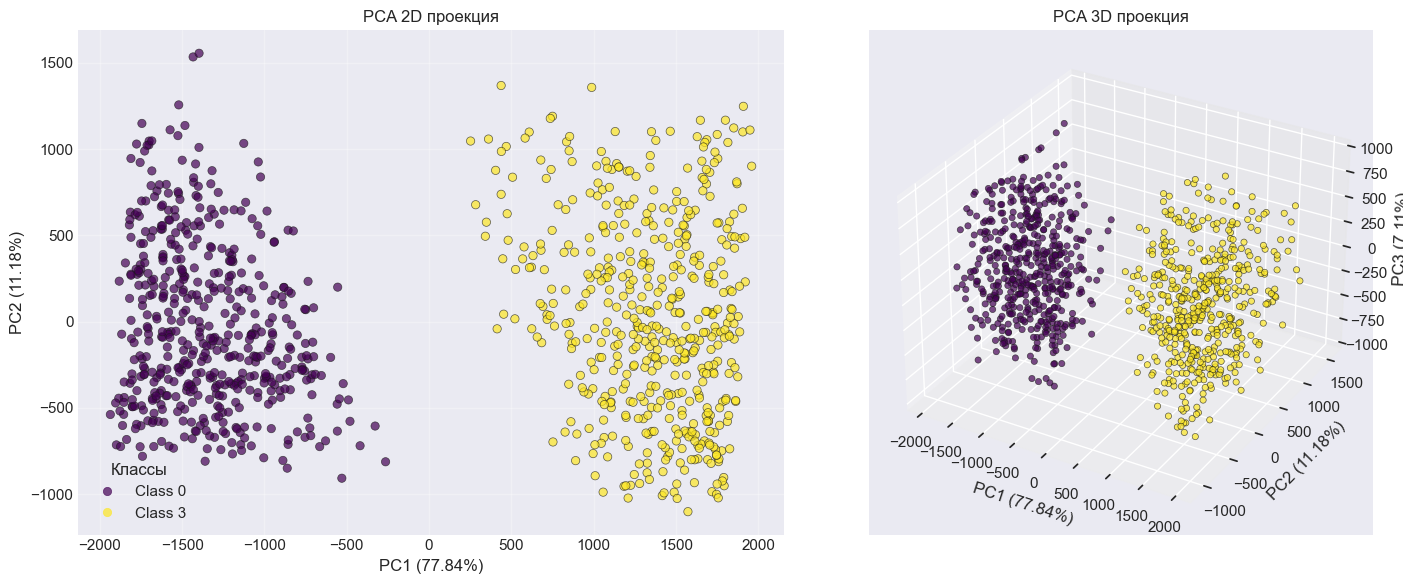

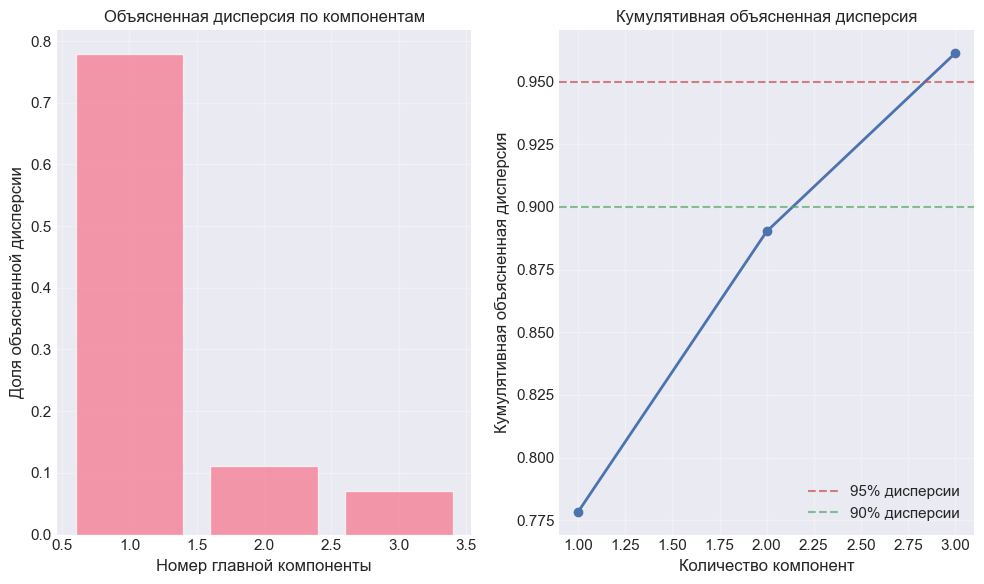


4. Визуализация t-SNE


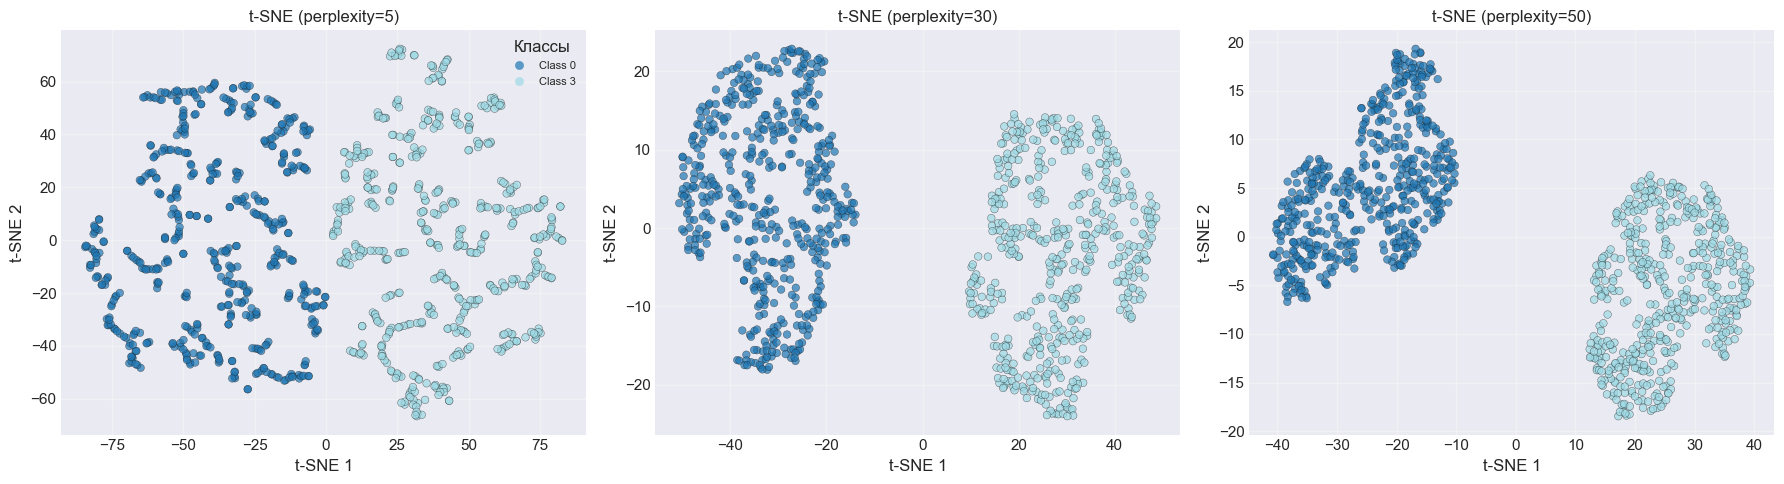


6. Параллельные координаты


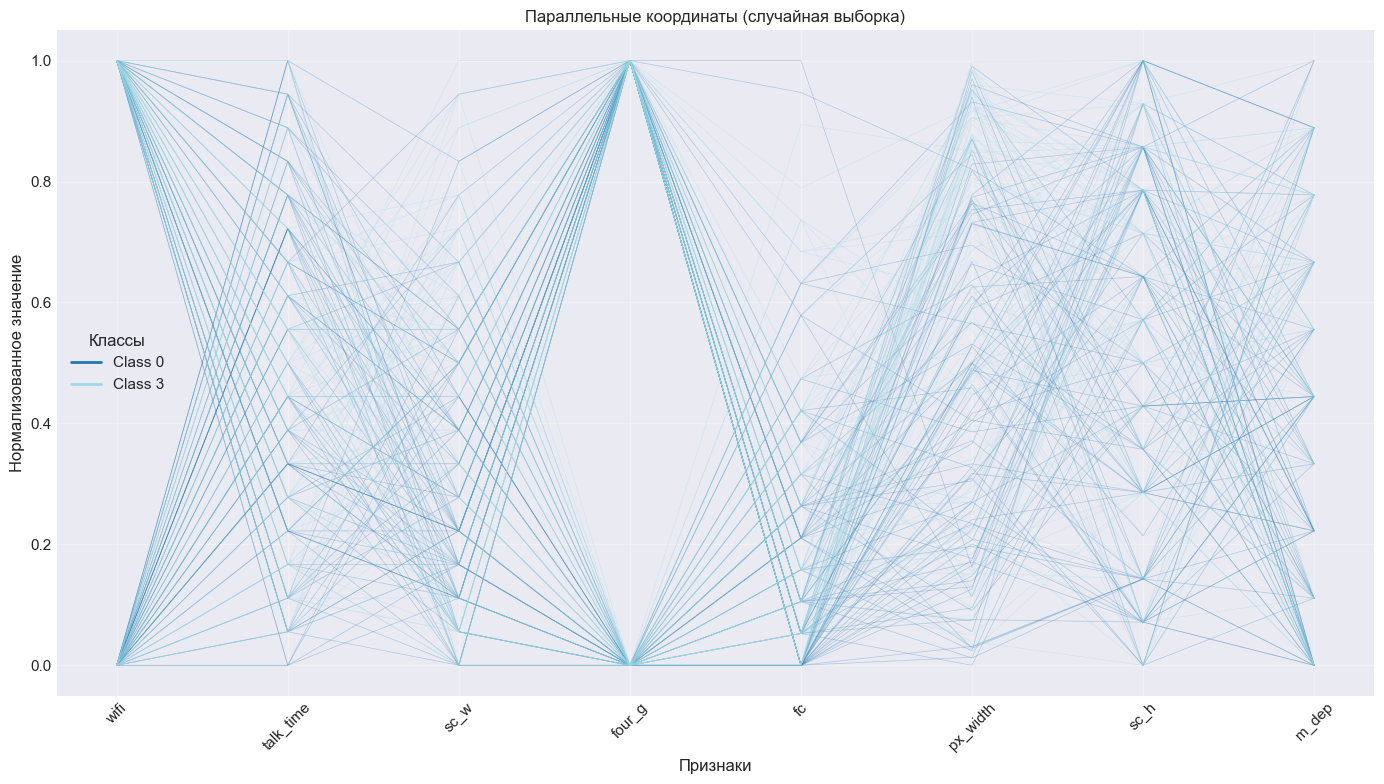


7. Радар-чарты по классам


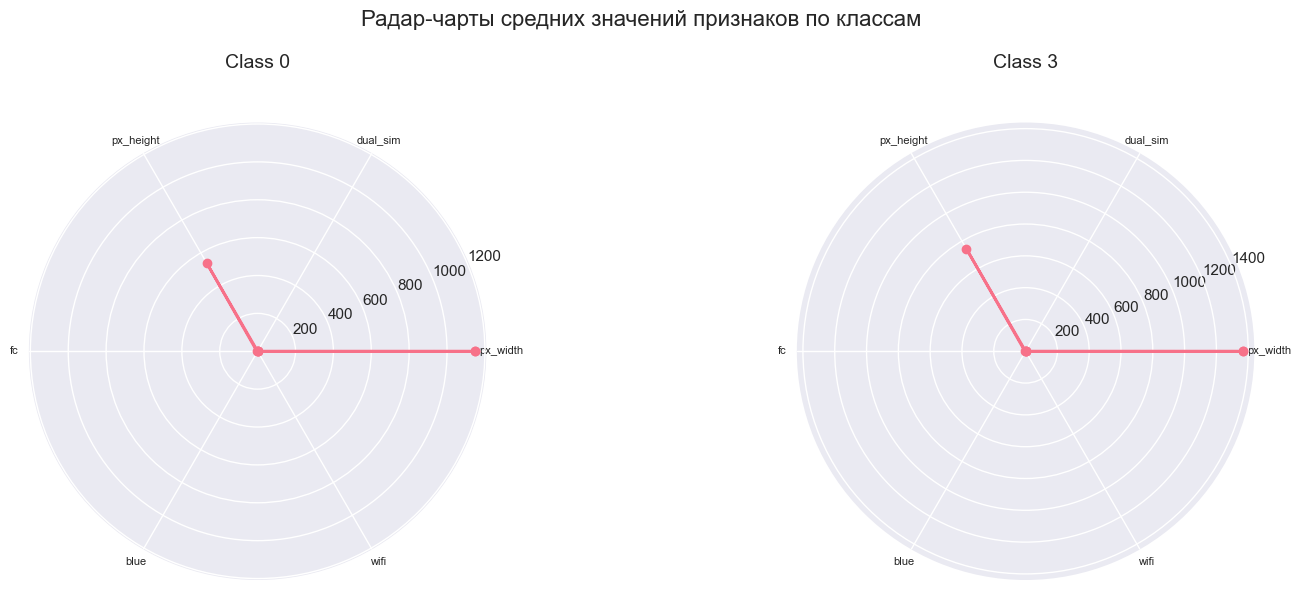


9. Сравнение методов уменьшения размерности
  Применяем PCA...
  Применяем t-SNE...
  Применяем MDS...
  Применяем Isomap...
  Применяем UMAP...


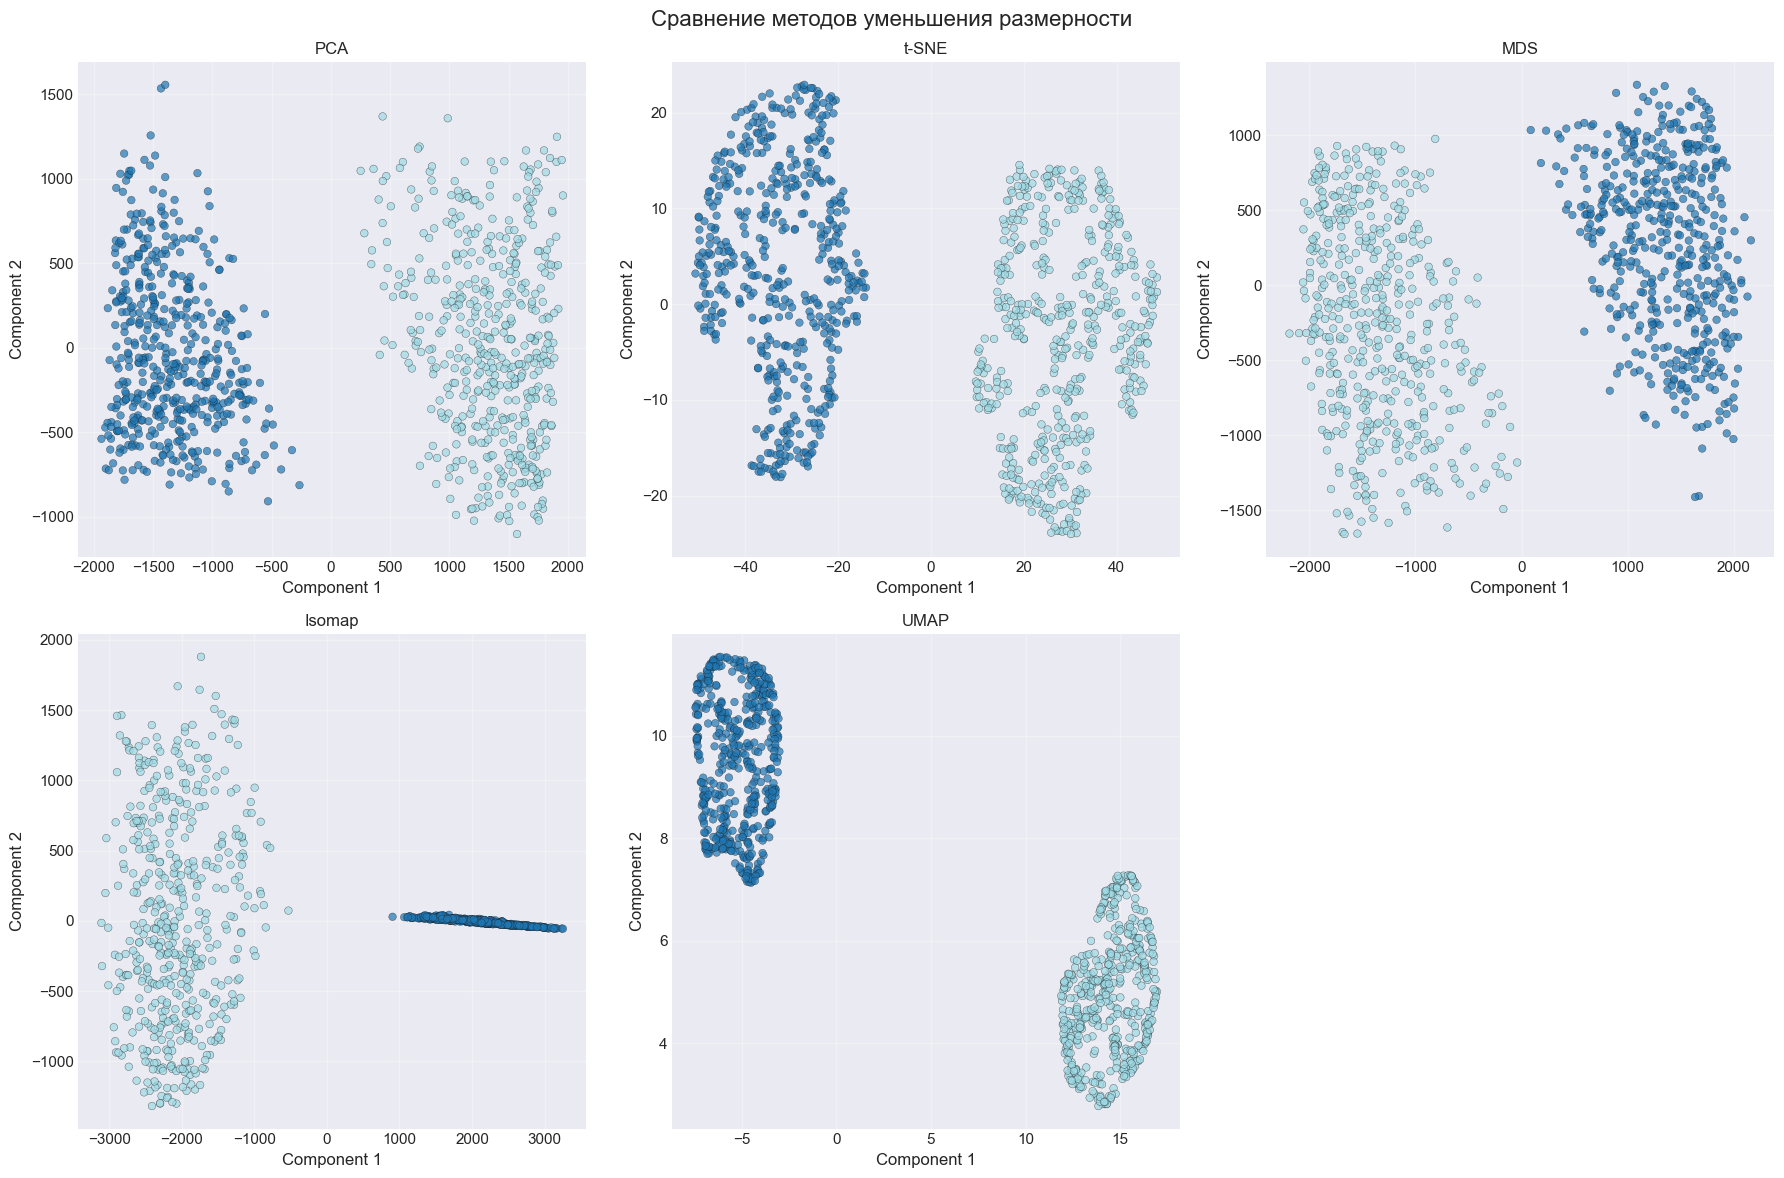


5. Визуализация UMAP


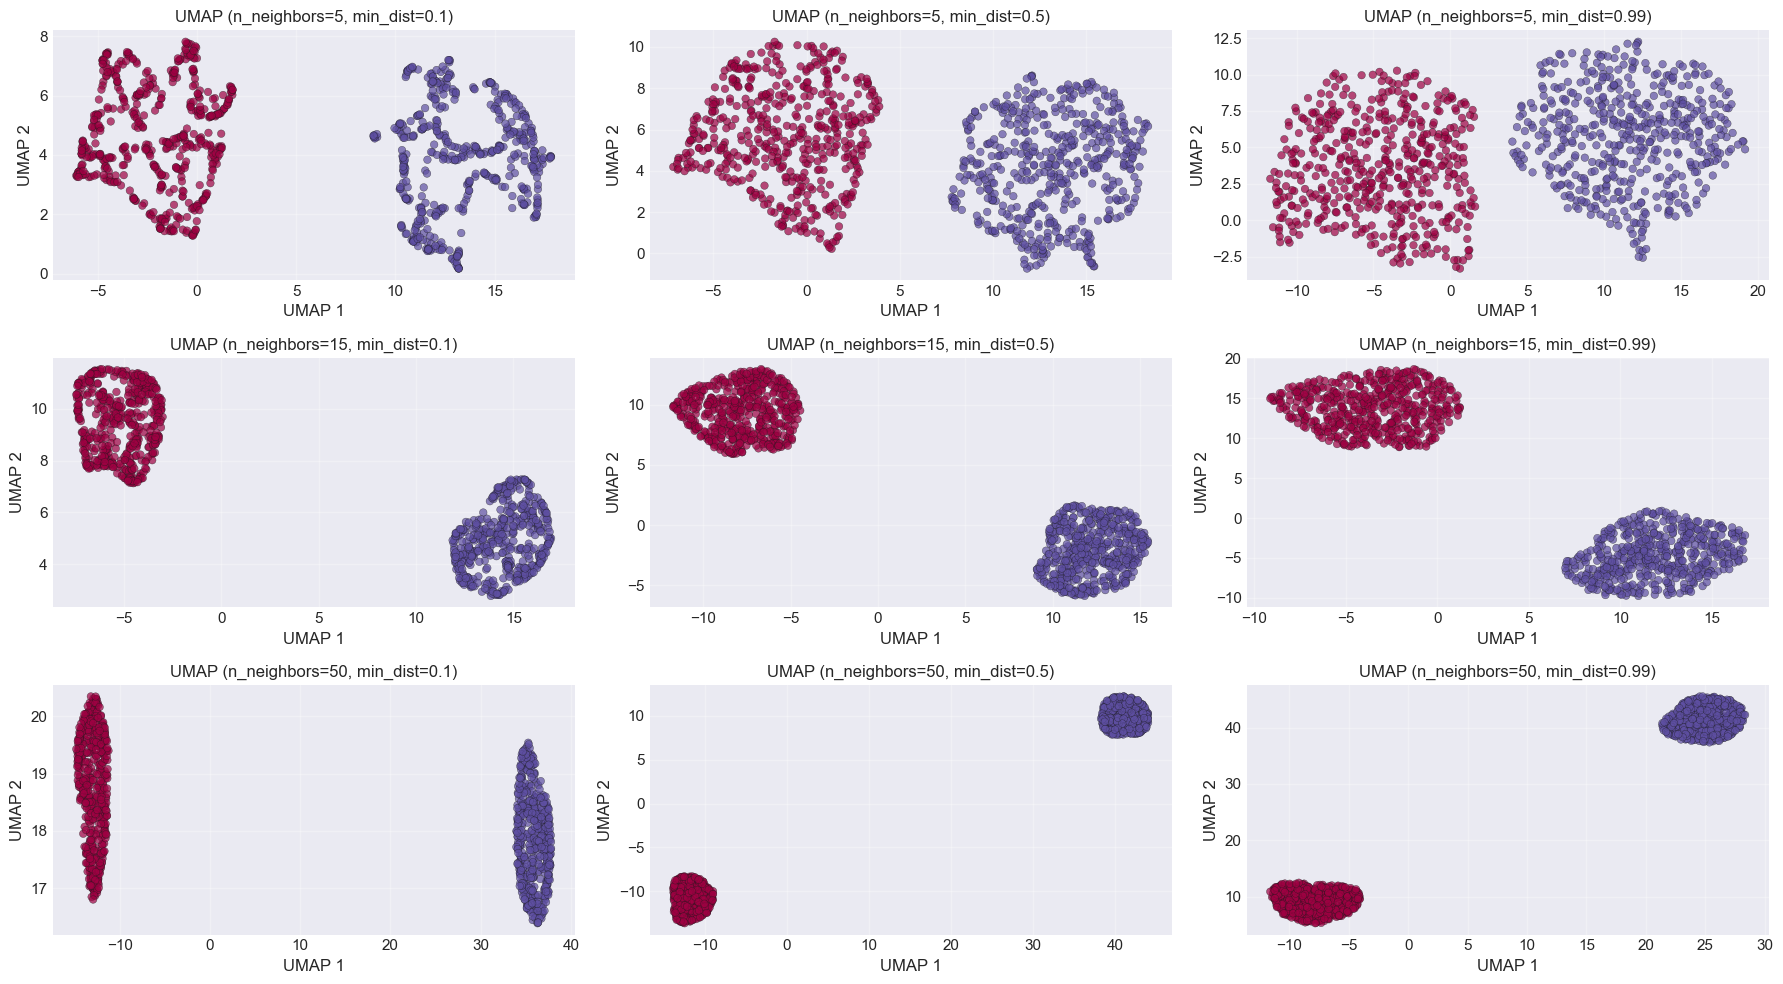


8. Интерактивная 3D визуализация (откроется в браузере)
  График сохранен в файл: interactive_3d_plot.html


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [25]:
# Инициализация визуализатора
visualizer = HighDimVisualizer(random_state=42)

# Выбор типа данных
print("Выберите тип данных для визуализации:")
print("1. Синтетические классификационные данные")
print("2. Комплексные данные (кластеры + полумесяцы)")
print("3. Данные о телефонах")

choice = input("Введите номер (1, 2 или 3, по умолчанию 1): ").strip()

if choice == "2":
    X, y, feature_names = visualizer.generate_complex_data(n_samples=500)
elif choice == "1":
    X, y, feature_names = visualizer.generate_sample_data(
        n_samples=300,  # Уменьшено для скорости
        n_features=15,
           n_classes=4
    )
else:
    X, y, feature_names = df[feature_cols].values, df["price_range"].values, feature_cols

# Базовая информация о данных
print(f"\nИнформация о данных:")
print(f"  Размер: {X.shape}")
print(f"  Количество классов: {len(np.unique(y))}")
print(f"  Количество признаков: {X.shape[1]}")
print(f"  Минимум: {X.min():.3f}, Максимум: {X.max():.3f}")
print(f"  Среднее: {X.mean():.3f}, Стандартное отклонение: {X.std():.3f}")

# Запуск визуализации
visualizer.run_full_visualization(X, y, feature_names)